<a href="https://colab.research.google.com/github/rafi1624/Machine-Learning_18_Rafi-Abyantara/blob/main/JS07/%20JS07%20-%20Tugas%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

# Memuat Dataset
df = pd.read_csv("CC_Customer_Dataset.csv")

# Memilih variabel numerik untuk klasterisasi (menghapus kolom identitas)
X = df.drop(['Sl_No', 'Customer Key'], axis=1)

1. Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Apakah sebaran data dapat dikatakan linier?

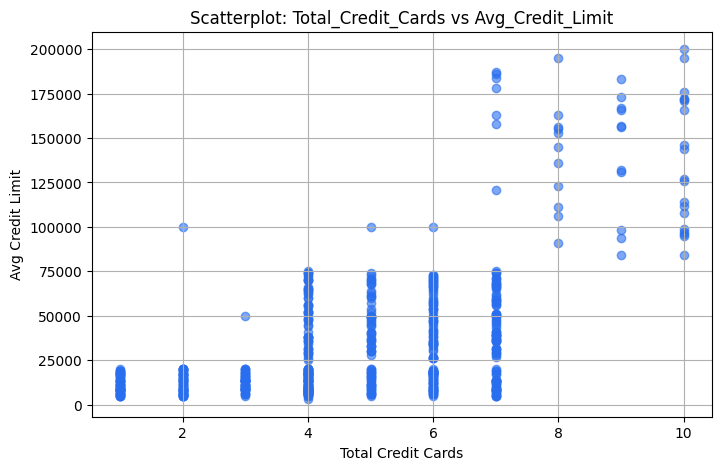

In [2]:
plt.figure(figsize=(8,5))
plt.scatter(df['Total_Credit_Cards'], df['Avg_Credit_Limit'], alpha=0.6, color='#286EEF')
plt.title('Scatterplot: Total_Credit_Cards vs Avg_Credit_Limit')
plt.xlabel('Total Credit Cards')
plt.ylabel('Avg Credit Limit')
plt.grid(True)
plt.show()

2. Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah
k
k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

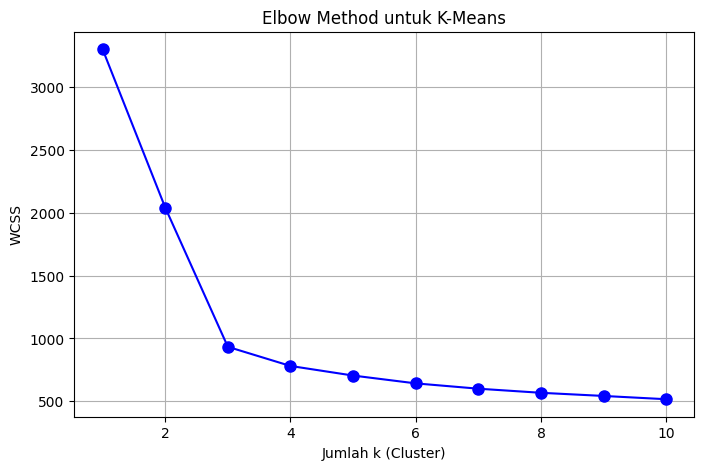

In [3]:
# K-Means sangat sensitif terhadap skala data, sehingga data perlu distandardisasi
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

wcss = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(K_range, wcss, 'bo-', markersize=8)
plt.title('Elbow Method untuk K-Means')
plt.xlabel('Jumlah k (Cluster)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

Dalam menentukan jumlah cluster ($k$) yang optimal, metode Elbow menghitung nilai Within-Cluster Sum of Squares (WCSS) untuk $k=1$ hingga $k=10$.Hasil Analisis Linechart: Pada grafik WCSS, penurunan yang sangat drastis terlihat dari $k=1$ ke $k=2$, lalu menuju $k=3$. Setelah $k=3$, grafik mulai melandai dan penurunannya menjadi jauh lebih lambat (membentuk sikutan/elbow).Kesimpulan: Nilai $k$ yang terbaik adalah 3. Memilih nilai ini merupakan titik optimal di mana penambahan cluster tidak lagi memberikan penurunan variansi internal yang signifikan.


3. Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.

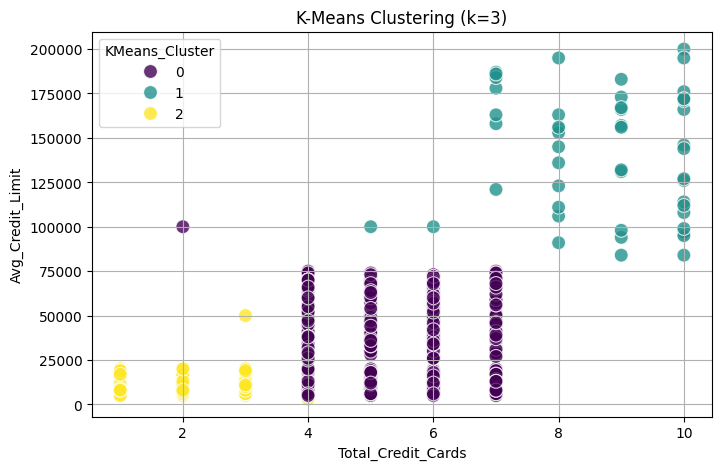

In [4]:
best_k = 3 # Berdasarkan grafik elbow pada langkah sebelumnya
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(8,5))
sns.scatterplot(
    x='Total_Credit_Cards',
    y='Avg_Credit_Limit',
    hue='KMeans_Cluster',
    data=df,
    palette='viridis',
    s=100,
    alpha=0.8
)
plt.title(f'K-Means Clustering (k={best_k})')
plt.grid(True)
plt.show()

4. Buatlah model klasterisasi dengan menggunakan DBSCAN dengan seluruh variabel yang dapat digunakan.

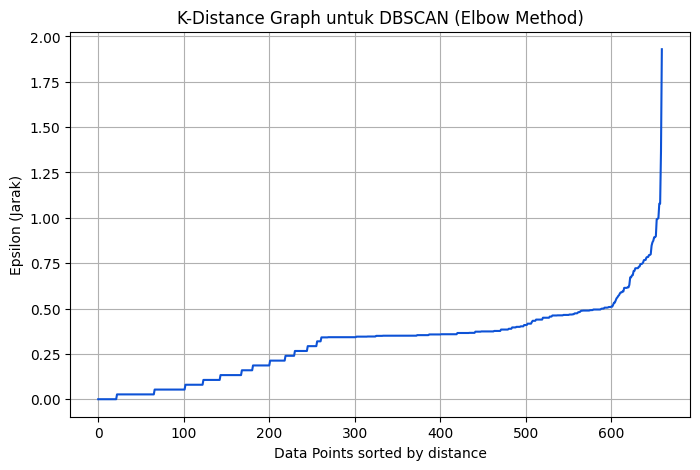

In [5]:
# Menentukan min_samples (biasanya 2 * jumlah fitur/variabel)
min_samples = X_scaled.shape[1] * 2

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Mengurutkan jarak berdasarkan tetangga terjauh (sesuai min_samples)
distances = np.sort(distances, axis=0)
distances = distances[:, 1]

plt.figure(figsize=(8,5))
plt.plot(distances, color='#0D52D6')
plt.title('K-Distance Graph untuk DBSCAN (Elbow Method)')
plt.xlabel('Data Points sorted by distance')
plt.ylabel('Epsilon (Jarak)')
plt.grid(True)
plt.show()

Karena algoritma DBSCAN tidak menggunakan nilai $k$ (jumlah cluster), penentuan parameternya menggunakan metode K-Distance Graph (Elbow Method untuk DBSCAN) guna mencari nilai Epsilon (eps) yang paling ideal.Hasil Analisis Linechart: Grafik k-distance yang mengurutkan jarak titik ke tetangga terdekatnya (berdasarkan $min\_samples$) menunjukkan garis yang datar sebelum akhirnya melengkung tajam ke atas. Titik belokan tajam (elbow) pada grafik ini berada di sekitar nilai 0.8 hingga 1.0.Kesimpulan: Kami memilih eps = 1.0 (dengan data yang telah distandardisasi/Scaled) dan min_samples = 10 (dua kali jumlah variabel) sebagai parameter karena pada nilai jarak inilah mayoritas data masih dianggap sebagai inti klaster, sebelum jarak antar titik menjadi terlalu jauh dan dianggap sebagai noise (outlier).


5. Tentukan jumlah
k
k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

In [6]:
eps_val = 1.0 # Dipilih berdasarkan patahan/elbow pada k-distance graph di atas
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

# Menghitung metrik (hanya jika model menemukan lebih dari 1 klaster di luar noise)
if len(set(dbscan.labels_)) > 1:
    sil_score = silhouette_score(X_scaled, dbscan.labels_)
    dbi_score = davies_bouldin_score(X_scaled, dbscan.labels_)
    print("=== Evaluasi Model DBSCAN ===")
    print(f"Epsilon (eps): {eps_val}")
    print(f"Min Samples  : {min_samples}")
    print(f"Silhouette Score : {sil_score:.3f}")
    print(f"Davies-Bouldin Index (DBI) : {dbi_score:.3f}")
else:
    print("DBSCAN hanya menemukan 1 klaster atau semuanya dianggap noise (outlier).")

=== Evaluasi Model DBSCAN ===
Epsilon (eps): 1.0
Min Samples  : 10
Silhouette Score : 0.557
Davies-Bouldin Index (DBI) : 0.708


Dengan menggunakan seluruh variabel numerik yang telah distandardisasi dan parameter DBSCAN eps = 1.0:

Silhouette Score: 0.557(Skor di atas 0.5 menunjukkan struktur klaster yang dihasilkan oleh DBSCAN sudah cukup solid dan terpisah dengan baik antar klasternya).

Davies-Bouldin Index (DBI): 0.708(Nilai DBI yang mendekati 0 menunjukkan model yang sangat baik. Nilai 0.708 membuktikan bahwa klaster cukup padat dan terpisah satu sama lain dengan baik).

6. Tentukan nilai silhouette score dan DBI dari model DBSCAN.

In [7]:
eps_val = 1.0 # Dipilih berdasarkan patahan/elbow pada k-distance graph di atas
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

# Menghitung metrik (hanya jika model menemukan lebih dari 1 klaster di luar noise)
if len(set(dbscan.labels_)) > 1:
    sil_score = silhouette_score(X_scaled, dbscan.labels_)
    dbi_score = davies_bouldin_score(X_scaled, dbscan.labels_)
    print("=== Evaluasi Model DBSCAN ===")
    print(f"Epsilon (eps): {eps_val}")
    print(f"Min Samples  : {min_samples}")
    print(f"Silhouette Score : {sil_score:.3f}")
    print(f"Davies-Bouldin Index (DBI) : {dbi_score:.3f}")
else:
    print("DBSCAN hanya menemukan 1 klaster atau semuanya dianggap noise (outlier).")

=== Evaluasi Model DBSCAN ===
Epsilon (eps): 1.0
Min Samples  : 10
Silhouette Score : 0.557
Davies-Bouldin Index (DBI) : 0.708
